In [1]:
import numpy as np
import quantile_forest as qrf

In [2]:
X_train = np.load('../../output/data_eagles_vezhen/qrf/X_train2.npy')
y_train = np.load('../../output/data_eagles_vezhen/qrf/y_train2.npy')
X_test = np.load('../../output/data_eagles_vezhen/qrf/X_test2.npy')
y_test = np.load('../../output/data_eagles_vezhen/qrf/y_test2.npy')
X_val = np.load('../../output/data_eagles_vezhen/qrf/X_val2.npy')
y_val = np.load('../../output/data_eagles_vezhen/qrf/y_val2.npy')

SLIDINGW_STEPS = 5
N_OUT_FEATS = y_train.shape[-1]
N_INP_FEATS = X_train.shape[-1]

y_train = y_train.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_train = X_train.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_val = y_val.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_val = X_val.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_test = y_test.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_test = X_test.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))

In [3]:
best_params = {
    'n_estimators': 50,
    'max_depth': 64,
    'max_samples': 0.5,
    'max_features': 'sqrt',
    'max_samples_leaf': 5,
}

In [8]:
qrf_best = qrf.RandomForestQuantileRegressor(**best_params, n_jobs=-1, random_state=42)\
    .fit(X_train, y_train)

y_val_pred = qrf_best.predict(X_val, quantiles=[0.025, 0.975])
y_val_low = y_val_pred[:, :, 0]
y_val_high = y_val_pred[:, :, 1]

val_mmsis = np.load('../../output/data_eagles_vezhen/qrf/val-mmsis2.npy', allow_pickle=True)
val_days = np.load('../../output/data_eagles_vezhen/qrf/val-days2.npy', allow_pickle=True)

In [9]:
vezhen_y = np.load('../../output/data_eagles_vezhen/qrf/vezhen_y3.npy', allow_pickle=True)\
    .reshape((-1, 5*3))
vezhen_x = np.load('../../output/data_eagles_vezhen/qrf/vezhen_x3.npy', allow_pickle=True)\
    .reshape((-1, 5*20))
eagles_y = np.load('../../output/data_eagles_vezhen/qrf/eagles_y3.npy', allow_pickle=True)\
    .reshape((-1, 5*3))
eagles_x = np.load('../../output/data_eagles_vezhen/qrf/eagles_x3.npy', allow_pickle=True)\
    .reshape((-1, 5*20))

In [10]:
import pandas as pd

In [11]:
in_pi_mask = (y_val > y_val_low) & (y_val < y_val_high)
in_pi_mask = in_pi_mask.reshape((-1, 5, 3))

group_results = {}
for ix, (mmsi, day) in enumerate(zip(val_mmsis, val_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix, :, :] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix, :, :] )

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.array(pi_masks).mean(axis=1).mean(axis=0)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means[0],
        'delta_dif': means[1],
        'dif': means[2]
    })

df = pd.DataFrame(df)

thresh_delta_cog = np.quantile(df['delta_cog'], 0.05)
thresh_delta_dif = np.quantile(df['delta_dif'], 0.05)
thresh_dif = np.quantile(df['dif'], 0.05)

print( 'delta_cog limit:', np.quantile(df['delta_cog'], 0.05) )
print( 'delta_dif liimt:', np.quantile(df['delta_dif'], 0.05) )
print( 'dif liimt:', np.quantile(df['dif'], 0.05) )

delta_cog limit: 0.8754166666666666
delta_dif liimt: 0.8602406417112297
dif liimt: 0.8687637362637362


In [15]:
vezhen_y = np.load('../../output/data_eagles_vezhen/qrf/vezhen_y3.npy', allow_pickle=True)\
    .reshape((-1, 5*3))
vezhen_x = np.load('../../output/data_eagles_vezhen/qrf/vezhen_x3.npy', allow_pickle=True)\
    .reshape((-1, 5*20))
eagles_y = np.load('../../output/data_eagles_vezhen/qrf/eagles_y3.npy', allow_pickle=True)\
    .reshape((-1, 5*3))
eagles_x = np.load('../../output/data_eagles_vezhen/qrf/eagles_x3.npy', allow_pickle=True)\
    .reshape((-1, 5*20))

In [16]:
import matplotlib.pyplot as plt

0.9137931034482759


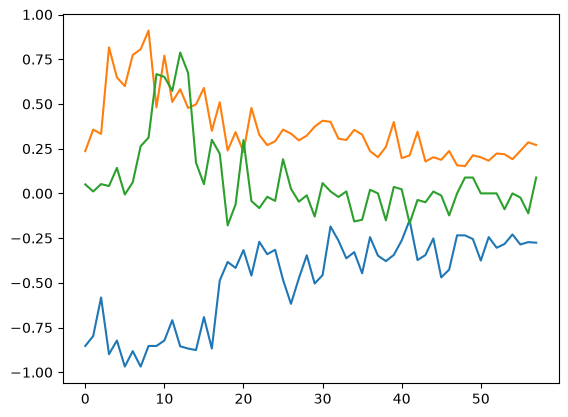

0.9


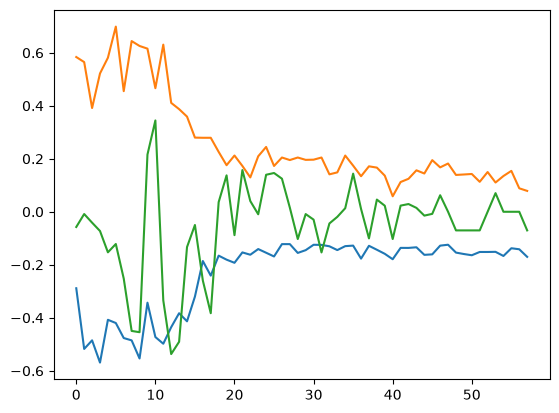

0.9448275862068966


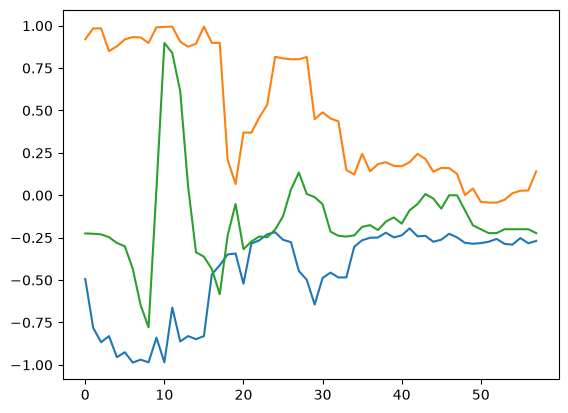

In [19]:
eagles_model_out = qrf_best.predict(eagles_x, quantiles=[0.025, 0.975])
eagles_low, eagles_high = eagles_model_out[:, :, 0], eagles_model_out[:, :, 1]

for feat in range(3):

    eagles_low_slice = eagles_low\
        .reshape((-1, 5, 3))\
        [:, :, feat]
    eagles_high_slice = eagles_high\
        .reshape((-1, 5, 3))\
        [:, :, feat]
    eagles_slice = eagles_y\
        .reshape((-1, 5, 3))\
        [:, :, feat]

    print(
        np.mean( (
            (eagles_low_slice < eagles_slice) &
            (eagles_high_slice > eagles_slice)
        ) )
    )

    plt.plot(eagles_low[:, feat])
    plt.plot(eagles_high[:, feat])
    plt.plot(eagles_y[:, feat])
    plt.show()

0.9502890173410404


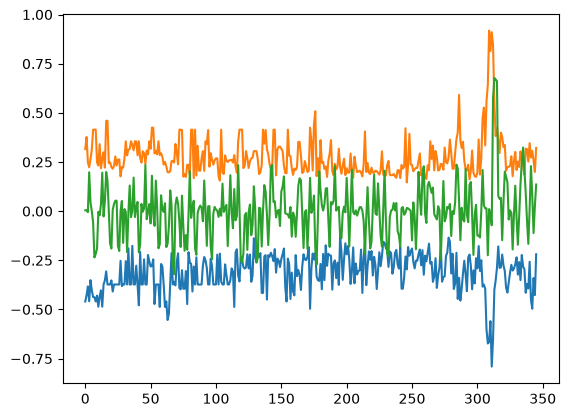

0.9393063583815029


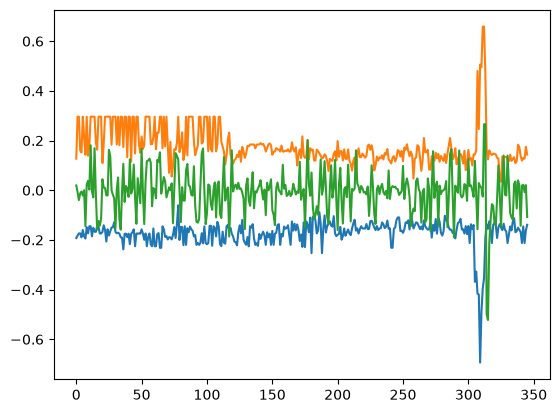

0.9549132947976878


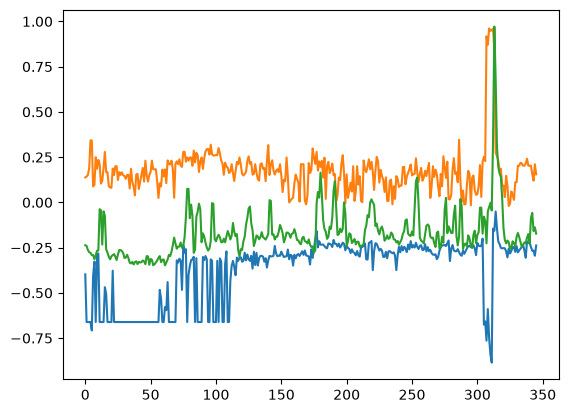

In [21]:
vezhen_model_out = qrf_best.predict(vezhen_x, quantiles=[0.025, 0.975])
vezhen_low, vezhen_high = vezhen_model_out[:, :, 0], vezhen_model_out[:, :, 1]

for feat in range(3):
    vezhen_low_slice = vezhen_low\
        .reshape((-1, 5, 3))\
        [:, :, feat]
    vezhen_high_slice = vezhen_high\
        .reshape((-1, 5, 3))\
        [:, :, feat]
    vezhen_slice = vezhen_y\
        .reshape((-1, 5, 3))\
        [:, :, feat]

    print(
        np.mean( (
            (vezhen_low_slice < vezhen_slice) &
            (vezhen_high_slice > vezhen_slice)
        ) )
    )

    plt.plot(vezhen_low[:, feat])
    plt.plot(vezhen_high[:, feat])
    plt.plot(vezhen_y[:, feat])
    plt.show()